In [1]:
import json
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

from contextlib import contextmanager

import h5py
import keras
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from keras.layers import GlobalAveragePooling2D
from keras.src.legacy.saving import legacy_h5_format, saving_utils
import keras.src.layers.layer as keras_layer_module

np.set_printoptions(suppress=True)


@contextmanager
def pick_vector_from_pair():
    """База Teachable Machine в Keras 3 отдаёт ДВА тензора, а голова ждёт один
    вектор (None, 1280). Пока собирается модель:
      1) если среди пары есть тензор нужного ранга - берём его;
      2) если оба - карты признаков (None, 7, 7, 1280), берём первую и сжимаем
         GlobalAveragePooling2D (так и получается 1280-мерный вектор).
    После сборки оригинальный Layer.__call__ возвращается."""
    orig_call = keras_layer_module.Layer.__call__

    def patched(self, *args, **kwargs):
        inputs = getattr(self, "inputs", None)
        if (
            isinstance(inputs, list)
            and len(inputs) == 1
            and len(args) == 1
            and isinstance(args[0], (list, tuple))
            and len(args[0]) == 2
        ):
            want_rank = len(inputs[0].shape)
            same_rank = [t for t in args[0] if len(t.shape) == want_rank]
            if same_rank:
                t = same_rank[0]
            else:
                t = args[0][0]
                if want_rank == 2 and len(t.shape) == 4:
                    t = GlobalAveragePooling2D()(t)
            args = (t,)
        return orig_call(self, *args, **kwargs)

    keras_layer_module.Layer.__call__ = patched
    try:
        yield
    finally:
        keras_layer_module.Layer.__call__ = orig_call


def describe_config(obj, depth=0):
    """Диагностика: выходы вложенных моделей и последние слои базы."""
    if isinstance(obj, dict):
        if "output_layers" in obj:
            names = [l["config"]["name"] if "config" in l else l.get("name") for l in obj.get("layers", [])]
            print("  " * depth, "модель:", obj.get("name"), "| output_layers:", obj["output_layers"], "| последние слои:", names[-4:])
        for v in obj.values():
            describe_config(v, depth + 1)
    elif isinstance(obj, list):
        for item in obj:
            describe_config(item, depth)


def clean_config(obj):
    """Убираем 'groups' (его не понимает DepthwiseConv2D в новом Keras)."""
    if isinstance(obj, dict):
        obj.pop("groups", None)
        for v in obj.values():
            clean_config(v)
    elif isinstance(obj, list):
        for item in obj:
            clean_config(item)


def load_tm_model(h5_path):
    with h5py.File(h5_path, "r") as f:
        model_config = f.attrs.get("model_config")
        if isinstance(model_config, bytes):
            model_config = model_config.decode("utf-8")
        config_dict = json.loads(model_config)
        clean_config(config_dict)
        describe_config(config_dict)

        with pick_vector_from_pair():
            model = saving_utils.model_from_config(config_dict)
        legacy_h5_format.load_weights_from_hdf5_group(f["model_weights"], model)
    return model


def iter_leaf_layers(layers_list):
    """Разворачиваем вложенные Sequential: именно их внутренний граф ломался
    на predict, а сами слои (с загруженными весами) в порядке."""
    for layer in layers_list:
        if isinstance(layer, keras.Sequential):
            yield from iter_leaf_layers(layer.layers)
        else:
            yield layer


def build_inference_model(loaded):
    """Собираем чистый граф Input -> слои -> один выход из уже загруженных
    слоёв (веса те же). Между картой признаков (7, 7, 1280) и головой, которой
    нужен вектор (1280), ставим GlobalAveragePooling2D."""
    inp = keras.Input(shape=(224, 224, 3))
    x = inp
    for layer in iter_leaf_layers(loaded.layers):
        print("  слой:", type(layer).__name__, layer.name)
        if isinstance(x, (list, tuple)):
            x = x[0]
        if isinstance(layer, keras.layers.Dense):
            want_rank = 2
        else:
            try:
                want_rank = len(layer.inputs[0].shape)
            except Exception:
                want_rank = None
        if want_rank == 2 and len(x.shape) == 4:
            x = GlobalAveragePooling2D()(x)
        x = layer(x)
    if isinstance(x, (list, tuple)):
        x = x[0]
    return keras.Model(inp, x)


loaded_model = load_tm_model("./models/keras_model.h5")
model = build_inference_model(loaded_model)
print("Вход:", model.input_shape, "| выход:", model.output_shape)

with open("./models/labels.txt", "r", encoding="utf-8") as f:
    class_names = [line.strip() for line in f if line.strip()]

print("✅ Модель успешно загружена! Классы:", class_names)


I0000 00:00:1795370074.597245  106664 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795370075.564650  106664 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


           модель: model10 | output_layers: [['out_relu', 0, 0]] | последние слои: ['block_16_project_BN', 'Conv_1', 'Conv_1_bn', 'out_relu']
  слой: Functional model10
  слой: GlobalAveragePooling2D global_average_pooling2d_GlobalAveragePooling2D10
  слой: Dense dense_Dense19
  слой: Dense dense_Dense20
Вход: (None, 224, 224, 3) | выход: (None, 2)
✅ Модель успешно загружена! Классы: ['0 hotdog 1', '1 nohoddog 2']


/home/yaekitsune/Projects/MOIBD_college_learning_machine_learn/teachable_machine/.venv/lib/python3.14/site-packages/keras/src/layers/core/dense.py:97: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



=== Проверка папки: hot_dog_validation (Всего фото: 250) ===


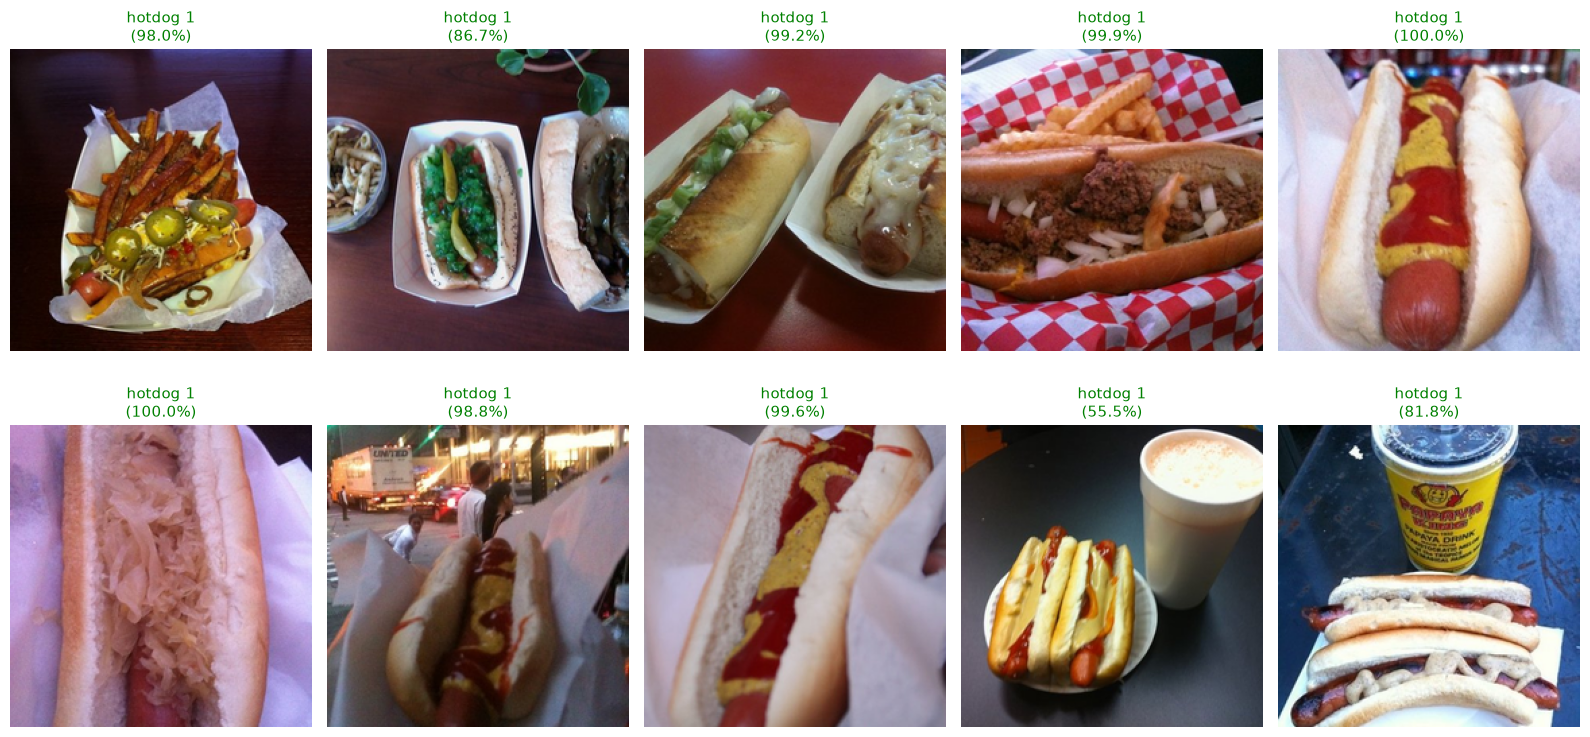

Итог по папке 'hot_dog_validation':
Правильно угадано: 210 из 250 (84.0%)
------------------------------------------------------------

=== Проверка папки: not_hot_dog_validation (Всего фото: 250) ===


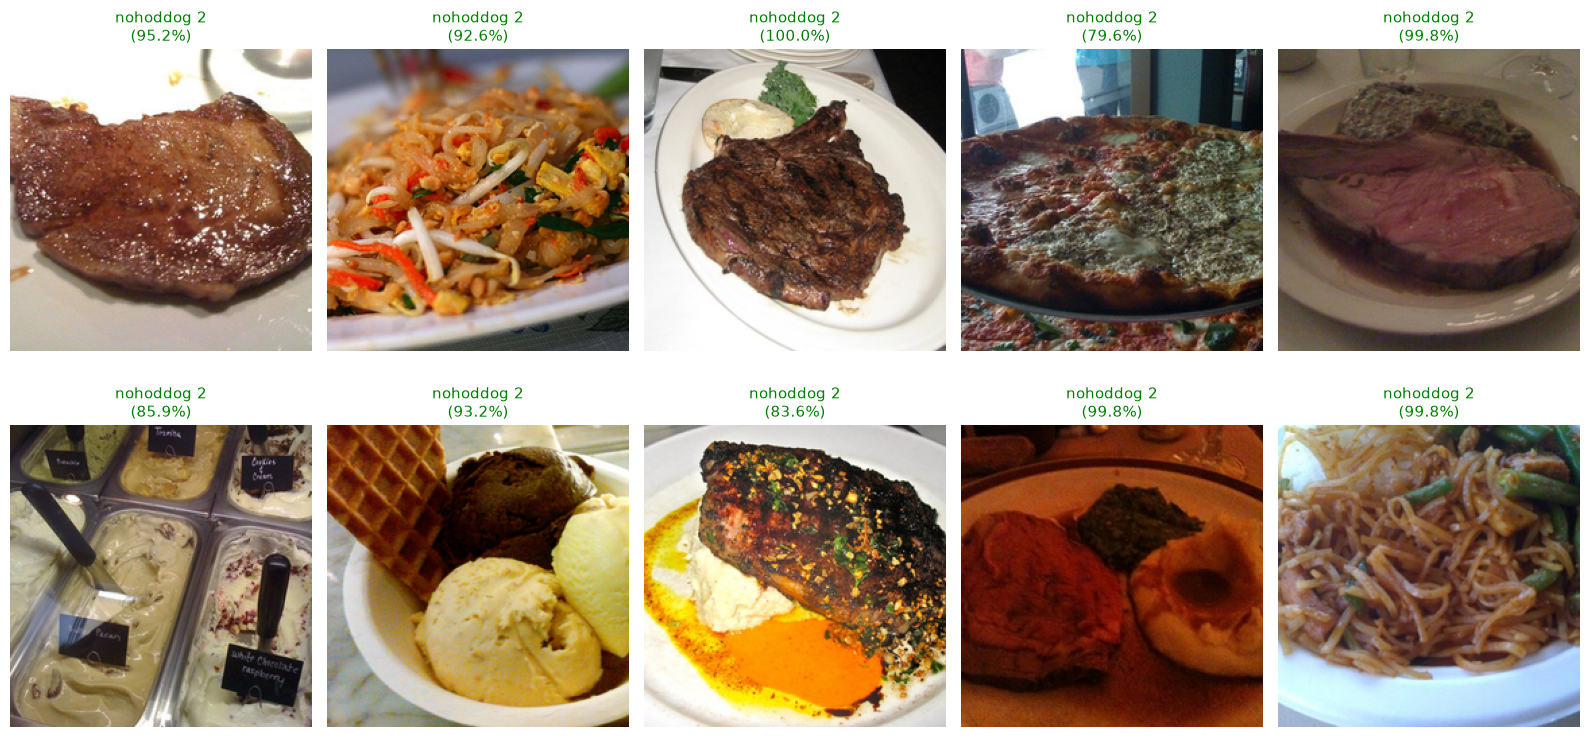

Итог по папке 'not_hot_dog_validation':
Правильно угадано: 224 из 250 (89.6%)
------------------------------------------------------------


In [2]:
def predict_image(image_path):
    data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)
    image = Image.open(image_path).convert("RGB")
    image = ImageOps.fit(image, (224, 224), Image.Resampling.LANCZOS)
    data[0] = np.asarray(image).astype(np.float32) / 127.5 - 1

    prediction = model.predict(data, verbose=0)
    index = int(np.argmax(prediction))
    name = class_names[index]
    class_name = name.split(" ", 1)[1] if " " in name else name
    confidence_score = float(prediction[0][index])
    return image, index, class_name, confidence_score


def evaluate_folder(folder_path, expected_class_index, show_count=10):
    files = sorted(
        f
        for f in os.listdir(folder_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg", ".webp"))
    )
    total_files = len(files)
    correct_predictions = 0

    print(f"\n=== Проверка папки: {folder_path} (Всего фото: {total_files}) ===")
    show_count = min(show_count, total_files, 10)
    if show_count > 0:
        fig, axes = plt.subplots(2, 5, figsize=(16, 8))
        axes = axes.flatten()
        for ax in axes:
            ax.axis("off")

    for i, file in enumerate(files):
        img, pred_index, pred_name, conf = predict_image(os.path.join(folder_path, file))
        is_correct = pred_index == expected_class_index
        correct_predictions += is_correct

        if i < show_count:
            axes[i].imshow(img)
            axes[i].set_title(
                f"{pred_name}\n({conf*100:.1f}%)",
                color="green" if is_correct else "red",
                fontsize=11,
            )

    if show_count > 0:
        plt.tight_layout()
        plt.show()

    accuracy = correct_predictions / total_files * 100 if total_files else 0
    print(f"Итог по папке '{folder_path}':")
    print(f"Правильно угадано: {correct_predictions} из {total_files} ({accuracy:.1f}%)")
    print("-" * 60)


evaluate_folder("hot_dog_validation", expected_class_index=0, show_count=10)
evaluate_folder("not_hot_dog_validation", expected_class_index=1, show_count=10)
